In [1]:
import sys
sys.path.append("..")

In [2]:
from src.style_transfer import run_style_transfer
from src.image_utils import load_image, save_image
from src.vgg import VGGFeatures

In [3]:
device = "cuda"
extractor = VGGFeatures().to(device)

In [4]:
content_paths = ["../data/content/Abyssinian_24.jpg",
                 "../data/content/beagle_10.jpg"]
style_paths = ["../data/style/starry_night.jpg",
               "../data/style/great_wave.jpg"]

In [5]:
from pathlib import Path

def to_img(t):
    return t.detach().cpu().squeeze(0).permute(1, 2, 0).numpy()

contents = {Path(p).stem: load_image(p, 384, device) for p in content_paths}
styles = {Path(p).stem: load_image(p, 384, device) for p in style_paths}

In [6]:
results = {}
for c_name, c_img in contents.items():
    for s_name, s_img in styles.items():
        out, hist = run_style_transfer(
            extractor, c_img, s_img,
            steps=500, style_weight=1e4, tv_weight=100, log_every=0,
        )
        save_image(out, f"../outputs/grid_{c_name}_{s_name}.png")
        results[(c_name, s_name)] = out
        print(f"{c_name} + {s_name}: final c={hist[-1][1]:.2f}  s={hist[-1][2]:.5f}")

Abyssinian_24 + starry_night: final c=9.73  s=0.00082
Abyssinian_24 + great_wave: final c=30.15  s=0.00200
beagle_10 + starry_night: final c=13.77  s=0.00077
beagle_10 + great_wave: final c=28.60  s=0.00167


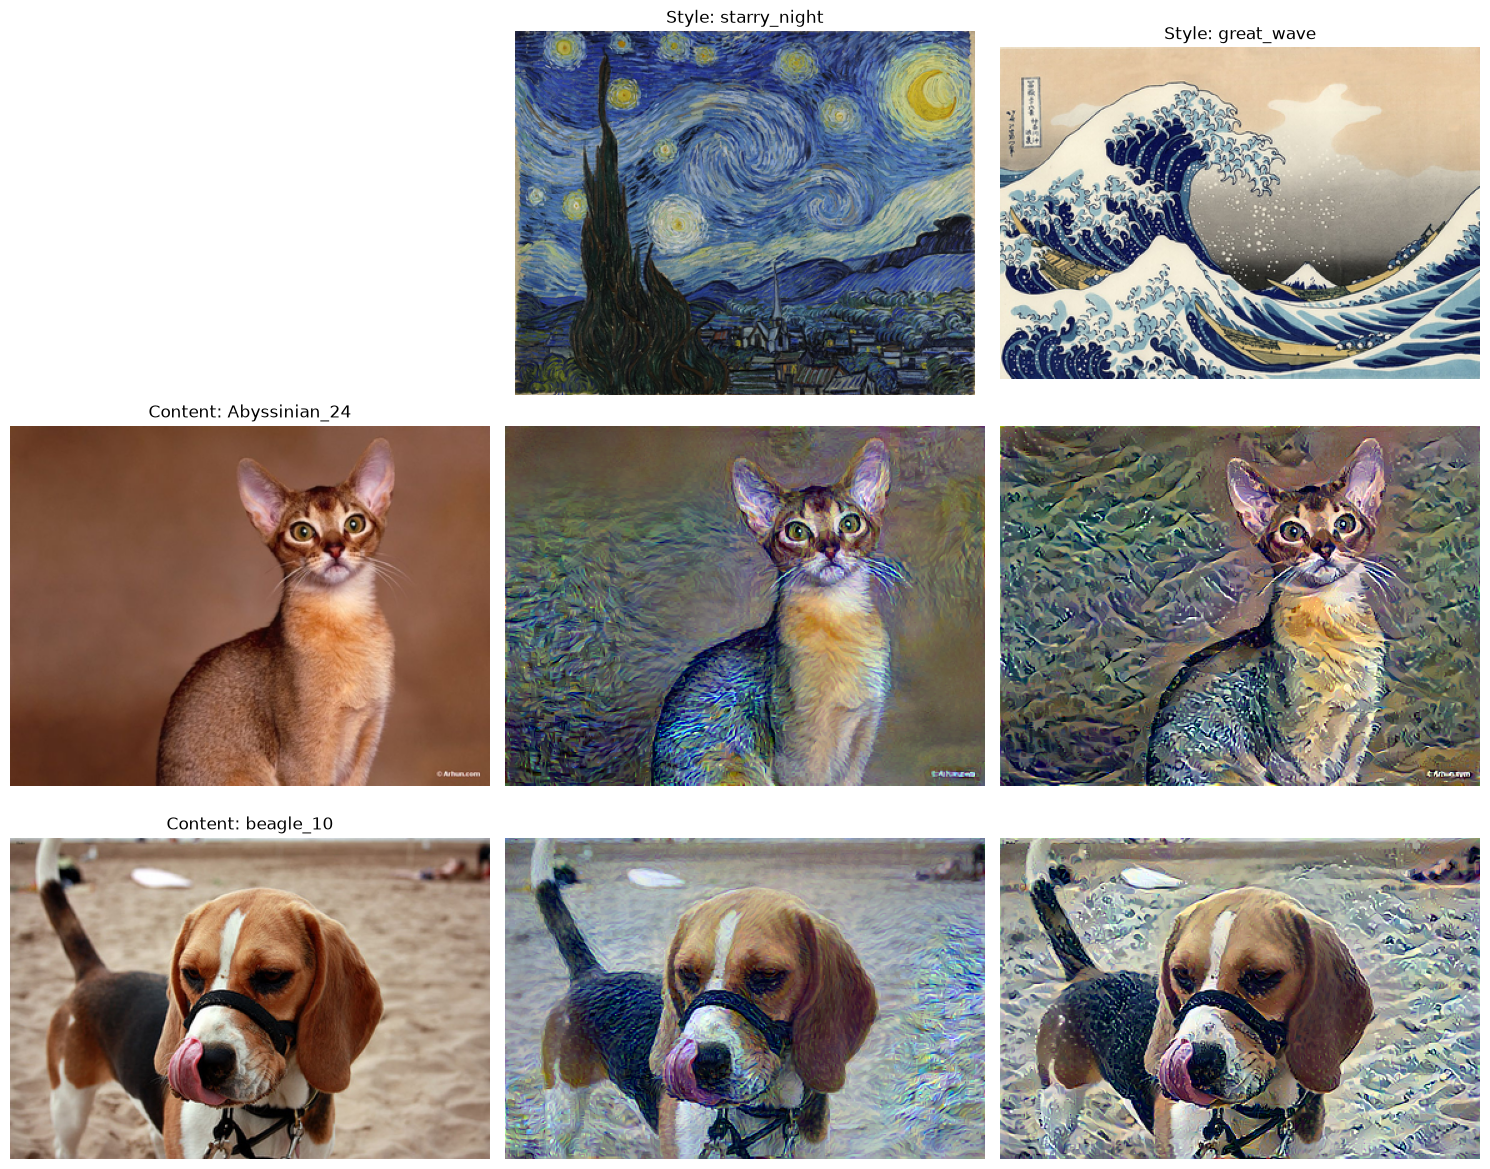

In [7]:
import matplotlib.pyplot as plt

c_names, s_names = list(contents), list(styles)
rows, cols = len(c_names) + 1, len(s_names) + 1
fig, ax = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
for a in ax.ravel():
    a.axis("off")

for j, s in enumerate(s_names):
    ax[0, j + 1].imshow(to_img(styles[s]))
    ax[0, j + 1].set_title("Style: " + s)

for i, c in enumerate(c_names):
    ax[i + 1, 0].imshow(to_img(contents[c]))
    ax[i + 1, 0].set_title("Content: " + c)
    for j, s in enumerate(s_names):
        ax[i + 1, j + 1].imshow(to_img(results[(c, s)]))

plt.tight_layout()
fig.savefig("../outputs/results_grid.png", dpi=150)
plt.show()